# Analyse du catalogue Steam

Ce notebook répond à mes cinq questions métier à partir du fichier propre produit par le notebook 02. Pour chaque question, je fais le calcul, un graphique, puis j'écris ma conclusion.

## Questions métier
1. Quels genres dominent le catalogue, et leur part évolue-t-elle dans le temps ?
2. Les jeux Indie sont-ils moins chers que les autres ?
3. Les réductions sont-elles plus fréquentes sur certains genres ?
4. Plus de langues supportées = de meilleurs avis ?
5. Combien de jeux sortent par mois ?

## 0. Chargement du fichier propre

- Je charge `steam_clean.csv` en typant dès la lecture : `date_sortie` en vraie date et `en_reduction` en booléen avec valeurs manquantes.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv(
    "../data/processed/steam_clean.csv",
    parse_dates=["date_sortie"],
    dtype={"en_reduction": "boolean"},
)
df.shape

(37618, 12)

## 1. Question 1 : quels genres dominent le catalogue ?

- Un jeu peut avoir plusieurs genres, écrits dans une seule cellule (`Action,Adventure,Indie`). Je les sépare pour avoir une ligne par couple jeu et genre.

In [2]:
genres_jeux = df[["url", "genre", "date_sortie"]].copy()
genres_jeux["genre"] = genres_jeux["genre"].str.split(",")
genres_jeux = genres_jeux.explode("genre")
genres_jeux["genre"] = genres_jeux["genre"].str.strip()
genres_jeux.shape, genres_jeux["genre"].nunique()

((97912, 3), 25)

- Les 25 genres ne sont pas de même nature : *Action* est un genre de jeu, *Indie* ou *Free to Play* un statut, *Utilities* un logiciel. Je construis une petite table qui range chaque genre dans une famille, puis je la joins.

In [3]:
familles = pd.DataFrame({
    "genre": [
        "Action", "Adventure", "Casual", "Simulation", "Strategy", "RPG",
        "Sports", "Racing", "Massively Multiplayer",
        "Indie", "Early Access", "Free to Play",
        "Design & Illustration", "Utilities", "Web Publishing",
        "Animation & Modeling", "Education", "Video Production",
        "Audio Production", "Software Training", "Photo Editing",
        "Game Development", "Accounting",
        "Movie", "Valve",
    ],
    "famille": (
        ["Genre de jeu"] * 9
        + ["Statut ou modèle"] * 3
        + ["Logiciel"] * 11
        + ["Autre"] * 2
    ),
})
familles.shape

(25, 2)

- Je joins cette table aux genres en `left` pour ne perdre aucune ligne. Je vérifie le nombre de lignes avant et après, et qu'aucun genre n'est resté sans famille.

In [4]:
nb_avant = len(genres_jeux)
genres_jeux = genres_jeux.merge(familles, on="genre", how="left", validate="many_to_one")
assert len(genres_jeux) == nb_avant
nb_avant, len(genres_jeux), genres_jeux["famille"].isna().sum()

(97912, 97912, np.int64(0))

In [5]:
genres_jeux["famille"].value_counts()

famille
Genre de jeu        67174
Statut ou modèle    28306
Logiciel             2430
Autre                   2
Name: count, dtype: int64

- Je calcule la part des jeux qui portent chacun des 10 genres les plus fréquents. Les parts dépassent 100 % au total, car un jeu a plusieurs genres.

In [6]:
part_genres = (genres_jeux["genre"].value_counts().head(10) / len(df) * 100).round(1)
part_genres

genre
Indie           60.8
Action          40.6
Casual          31.9
Adventure       31.6
Simulation      23.2
Strategy        21.2
RPG             18.5
Early Access     7.5
Free to Play     7.0
Sports           4.6
Name: count, dtype: float64

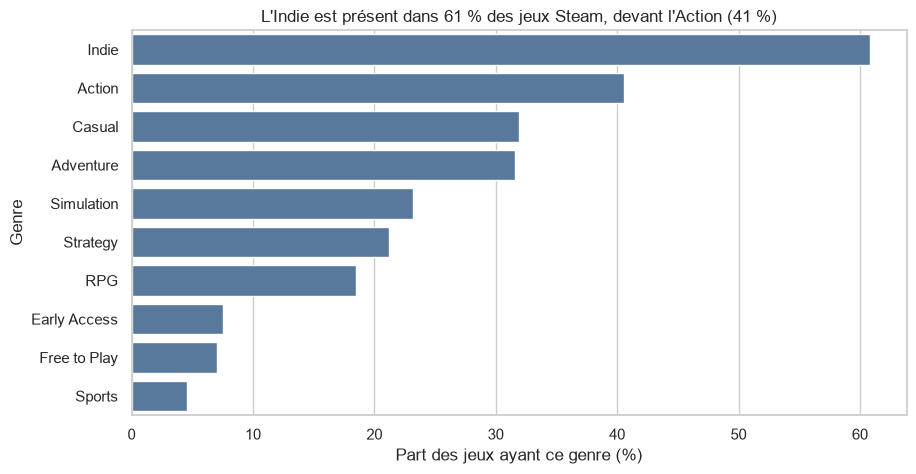

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=part_genres.values, y=part_genres.index, orient="h", color="#4C78A8", ax=ax)
ax.set_title("L'Indie est présent dans 61 % des jeux Steam, devant l'Action (41 %)")
ax.set_xlabel("Part des jeux ayant ce genre (%)")
ax.set_ylabel("Genre")
fig.savefig("../figures/genres_top10.png", dpi=150, bbox_inches="tight")
plt.show()

- Pour l'évolution, je croise l'année de sortie et le genre. Je garde 2013 à 2018 : avant 2013 il y a trop peu de jeux, et 2019 est incomplète (le jeu de données a été collecté vers juin 2019).

In [8]:
genres_annee = genres_jeux.dropna(subset=["date_sortie"]).copy()
genres_annee["annee"] = genres_annee["date_sortie"].dt.year
genres_annee = genres_annee[genres_annee["annee"].between(2013, 2018)]

effectifs = pd.crosstab(genres_annee["annee"], genres_annee["genre"])
jeux_par_annee = genres_annee.groupby("annee")["url"].nunique()
parts = effectifs[["Indie", "Action", "Casual", "Adventure"]].div(jeux_par_annee, axis=0) * 100
parts.round(1)

genre,Indie,Action,Casual,Adventure
annee,,,,
2013,35.7,43.1,18.0,23.9
2014,51.8,37.2,26.0,25.8
2015,59.4,42.6,26.4,32.4
2016,62.1,38.9,32.2,31.7
2017,64.2,40.7,34.5,33.6
2018,67.5,40.1,37.8,31.5


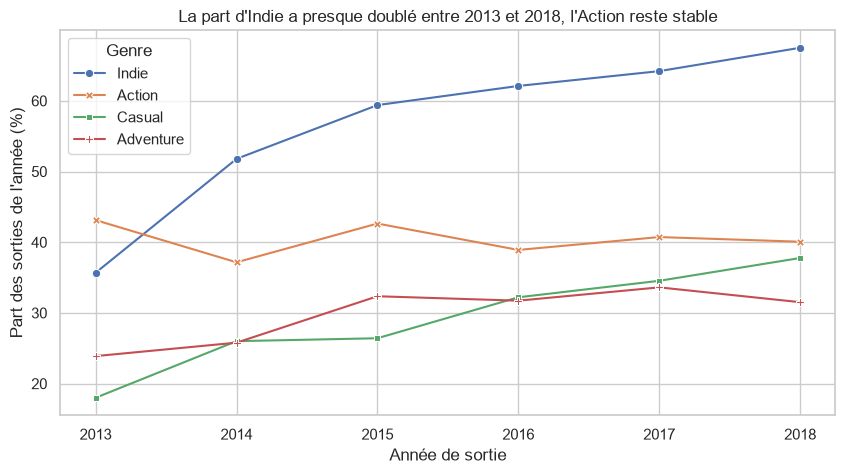

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=parts, dashes=False, markers=True, ax=ax)
ax.set_xticks(parts.index)
ax.set_title("La part d'Indie a presque doublé entre 2013 et 2018, l'Action reste stable")
ax.set_xlabel("Année de sortie")
ax.set_ylabel("Part des sorties de l'année (%)")
ax.legend(title="Genre")
fig.savefig("../figures/genres_evolution.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusion question 1** : l'Indie est le genre le plus fréquent (61 % des jeux), devant l'Action (41 %), Casual (32 %) et Adventure (32 %). Comme un jeu a plusieurs genres, ces parts ne s'additionnent pas.

Entre 2013 et 2018, la part d'Indie dans les sorties passe de 36 % à 68 % et celle de Casual de 18 % à 38 %, alors que l'Action reste stable autour de 40 %. L'année 2019 est exclue car incomplète.

## 2. Question 2 : les jeux Indie sont-ils moins chers que les autres ?

- Je crée une colonne qui dit si un jeu est Indie ou non, à partir de sa liste de genres.

In [10]:
df["est_indie"] = df["genre"].str.contains("Indie")
df["est_indie"].value_counts()

est_indie
True     22868
False    14750
Name: count, dtype: int64

- Les jeux gratuits (prix 0) ne se comparent pas à des jeux payants. Je vérifie d'abord qu'ils sont répartis de façon similaire entre les deux groupes, pour savoir si les écarter fausse la comparaison.

In [11]:
prix_connus = df.dropna(subset=["prix"])
prix_connus.groupby("est_indie")["prix"].apply(lambda s: (s == 0).mean() * 100).round(1)

est_indie
False    8.2
True     7.6
Name: prix, dtype: float64

In [12]:
payants = df[df["prix"] > 0].copy()
payants["groupe"] = payants["est_indie"].map({True: "Indie", False: "Autres jeux"})
payants.groupby("groupe")["prix"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
groupe,,,,,,,,
Autres jeux,12583.0,13.61,24.80,0.99,2.99,7.99,14.99,995.00
Indie,18763.0,9.13,14.88,0.50,2.99,4.99,9.99,203.95


- La part de jeux gratuits est proche dans les deux groupes (8 % et 8 %), donc je les écarte sans fausser la comparaison. Je compare les jeux payants dont le prix est connu.
- Je regarde la médiane en plus de la moyenne : quelques jeux très chers tirent la moyenne vers le haut.

- Pour comparer une mesure (le prix) entre deux catégories, la boîte à moustaches est adaptée : elle montre la médiane et la dispersion. J'arrête l'axe à 60 $ pour la lisibilité : 543 jeux payants dépassent ce prix et ne sont pas visibles.

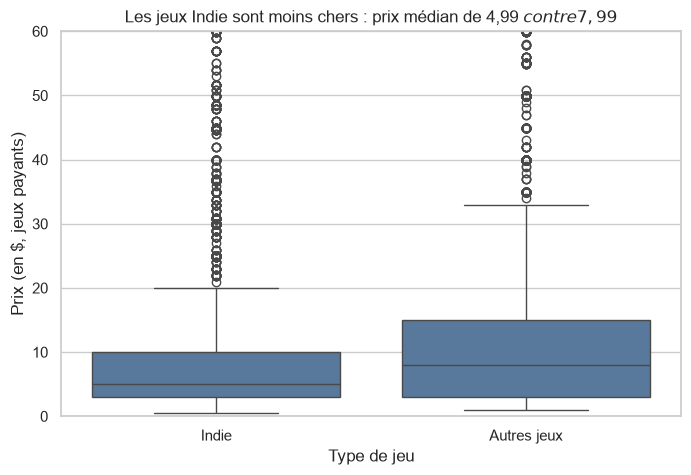

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=payants, x="groupe", y="prix", order=["Indie", "Autres jeux"], color="#4C78A8", ax=ax)
ax.set_ylim(0, 60)
ax.set_title("Les jeux Indie sont moins chers : prix médian de 4,99 $ contre 7,99 $")
ax.set_xlabel("Type de jeu")
ax.set_ylabel("Prix (en $, jeux payants)")
fig.savefig("../figures/prix_indie.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusion question 2** : oui, les jeux Indie sont moins chers. Sur 31 346 jeux payants dont le prix est connu, le prix médian est de 4,99 $ pour les Indie contre 7,99 $ pour les autres (moyenne : 9,13 $ contre 13,61 $). Trois quarts des Indie coûtent 9,99 $ ou moins, contre 14,99 $ pour les autres.

**Limites** : 3 600 jeux sans prix fiable et 2 672 jeux gratuits sont exclus de la comparaison. Les prix sont ceux de la période de collecte, et cet écart décrit une différence, il n'explique pas ses causes (les Indie sont plus souvent de petits jeux).

## 3. Question 3 : les réductions sont-elles plus fréquentes sur certains genres ?

- Je ne pourrai analyser seulement les jeux où `en_reduction` est connue : c'est à dire Vrai ou Faux. Je compterai aussi ces jeux et le taux de réduction global.

In [14]:
df["en_reduction"].notna().sum(), round(df["en_reduction"].mean() * 100, 1)

(np.int64(28323), np.float64(8.3))

- Je rattache `en_reduction` à la table des genres (une ligne par jeu et par genre) avec une jointure en `left`. Je vérifie le nombre de lignes avant et après, puis j'écarte les valeurs douteuses.

In [15]:
genres_red = genres_jeux.merge(df[["url", "en_reduction"]], on="url", how="left", validate="many_to_one")
assert len(genres_red) == len(genres_jeux)
genres_red = genres_red.dropna(subset=["en_reduction"]).copy()
genres_red["en_reduction"] = genres_red["en_reduction"].astype(bool)
len(genres_jeux), len(genres_red)

(97912, 74779)

- Je calcule, pour chaque genre, le nombre de jeux et le taux de réduction. Je garde les genres qui ont au moins 500 jeux, car un taux calculé sur quelques dizaines de jeux serait trop instable.

In [16]:
taux_genres = genres_red.groupby("genre").agg(
    jeux=("en_reduction", "size"),
    taux_reduction=("en_reduction", "mean"),
)
taux_genres["taux_reduction"] = (taux_genres["taux_reduction"] * 100).round(1)
taux_genres = taux_genres[taux_genres["jeux"] >= 500].sort_values("taux_reduction", ascending=False)
taux_genres

,jeux,taux_reduction
genre,,
Design & Illustration,529,13.8
Casual,9047,11.7
Sports,1353,10.8
Adventure,8558,10.4
Indie,17183,9.4
Strategy,5857,8.8
Racing,1002,8.5
Action,11650,7.6
RPG,5124,7.5


- Je représente ce taux par des barres horizontales triées, avec une ligne verticale pour le taux global de 8,3 %, qui sert de repère.

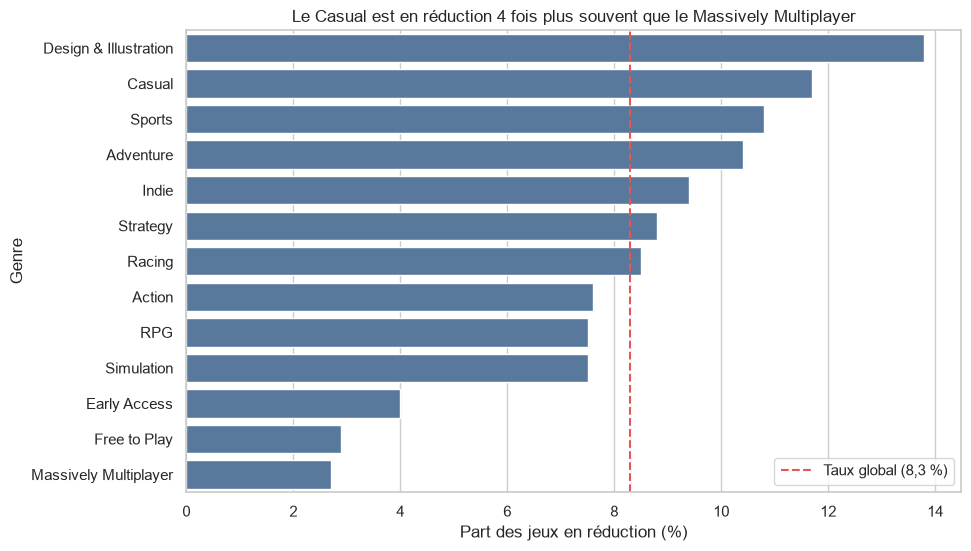

In [17]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    x=taux_genres["taux_reduction"], y=taux_genres.index,
    orient="h", color="#4C78A8", ax=ax,
)
ax.axvline(8.3, color="#E45756", linestyle="--", label="Taux global (8,3 %)")
ax.set_title("Le Casual est en réduction 4 fois plus souvent que le Massively Multiplayer")
ax.set_xlabel("Part des jeux en réduction (%)")
ax.set_ylabel("Genre")
ax.legend()
fig.savefig("../figures/reductions_genres.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusion question 3** : oui, la fréquence des réductions varie selon le genre. Sur les 28 323 jeux dont la réduction est fiable, 8,3 % sont en réduction. Les genres les plus souvent réduits sont Design & Illustration (13,8 %), Casual (11,7 %), Sports (10,8 %) et Adventure (10,4 %). Les moins réduits sont Massively Multiplayer (2,7 %), Free to Play (2,9 %) et Early Access (4,0 %).

**Limites** : ces trois derniers genres sont mécaniquement peu réduits, puisqu'un jeu gratuit ne peut pas l'être et que l'accès anticipé est souvent vendu au prix d'origine. De plus, 9 295 jeux (25 %) sont exclus car leur colonne `discount_price` n'est pas fiable, et un jeu sans `discount_price` est supposé ne pas être en réduction à la date de collecte.

## 4. Question 4 : plus de langues supportées, de meilleurs avis ?

- La colonne `languages` liste les langues séparées par des virgules (`English,French,German`). Le nombre de langues, c'est le nombre de virgules plus un.

In [18]:
df["nb_langues"] = df["languages"].str.count(",") + 1
df["nb_langues"].describe()

count    37618.000000
mean         4.013690
std          4.911163
min          1.000000
25%          1.000000
50%          2.000000
75%          6.000000
max         29.000000
Name: nb_langues, dtype: float64

- `all_reviews` mélange plusieurs informations dans un seul texte. Un exemple : `Very Positive,(390),- 89% of the 390 user reviews for this game are positive.` Je veux en tirer le nombre d'avis (390) et le pourcentage d'avis positifs (89).
- Pour cela j'utilise une expression régulière avec `str.extract`. Elle cherche un nombre entre parenthèses, puis un pourcentage suivi de « % of ».

In [19]:
extrait = df["all_reviews"].str.extract(r"\((?P<nb>[\d,]+)\),(?:\*,)?- (?P<pct>\d+)% of")
df["nb_avis"] = pd.to_numeric(extrait["nb"].str.replace(",", "", regex=False))
df["pct_positif"] = pd.to_numeric(extrait["pct"])
df["pct_positif"].notna().sum()

np.int64(17241)

- Tous les jeux n'ont pas de note. Je compte les trois cas : jeux avec une note, jeux avec avis mais sans note, jeux sans aucun avis.

In [20]:
sans_score = df["all_reviews"].notna() & df["pct_positif"].isna()
df["pct_positif"].notna().sum(), sans_score.sum(), df["all_reviews"].isna().sum()

(np.int64(17241), np.int64(10953), np.int64(9424))

In [21]:
df.loc[sans_score, "all_reviews"].str.contains("Need more user reviews").all()

np.True_

- Je garde les 17 241 jeux qui ont une note. Je regarde la distribution du pourcentage d'avis positifs.

In [22]:
avec_avis = df.dropna(subset=["pct_positif"]).copy()
avec_avis["pct_positif"].describe().round(1)

count    17241.0
mean        74.6
std         18.6
min          0.0
25%         64.0
50%         79.0
75%         89.0
max        100.0
Name: pct_positif, dtype: float64

- Je regroupe les jeux par nombre de langues avec `pd.cut` (1, 2-3, 4-6, 7-10, 11 et plus) et je compare le pourcentage d'avis positifs.

In [23]:
avec_avis["tranche"] = pd.cut(
    avec_avis["nb_langues"], bins=[0, 1, 3, 6, 10, 50],
    labels=["1", "2-3", "4-6", "7-10", "11+"],
)
par_tranche = avec_avis.groupby("tranche", observed=True).agg(
    jeux=("pct_positif", "size"),
    pct_moyen=("pct_positif", "mean"),
    pct_median=("pct_positif", "median"),
    avis_median=("nb_avis", "median"),
).round(1)
par_tranche

,jeux,pct_moyen,pct_median,avis_median
tranche,,,,
1,7191,73.8,78.0,42.0
2-3,3069,74.3,78.0,52.0
4-6,2451,74.2,78.0,102.0
7-10,2597,76.2,79.0,126.0
11+,1933,76.9,81.0,159.0


- Je représente le pourcentage médian d'avis positifs par tranche, avec un axe qui part de 0 pour ne pas exagérer les écarts.

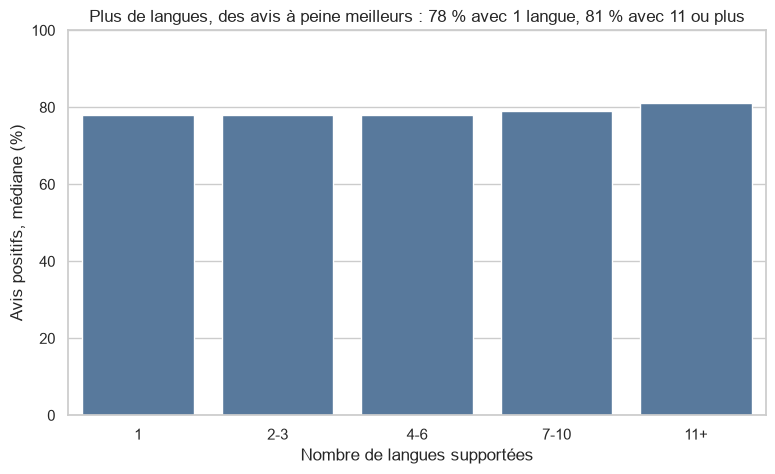

In [24]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=avec_avis, x="tranche", y="pct_positif",
    estimator="median", errorbar=None, color="#4C78A8", ax=ax,
)
ax.set_ylim(0, 100)
ax.set_title("Plus de langues, des avis à peine meilleurs : 78 % avec 1 langue, 81 % avec 11 ou plus")
ax.set_xlabel("Nombre de langues supportées")
ax.set_ylabel("Avis positifs, médiane (%)")
fig.savefig("../figures/langues_avis.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusion question 4** : non, ou à peine. Sur 17 241 jeux ayant une note, le pourcentage médian d'avis positifs passe de 78 % pour les jeux à une langue à 81 % pour ceux à 11 langues ou plus. La corrélation de Spearman, d'environ 0,05, est quasi nulle.

En revanche, les jeux multilingues reçoivent plus d'avis : 42 avis en médiane pour une langue, 159 pour 11 langues ou plus. Traduire un jeu va plutôt avec sa popularité qu'avec sa qualité perçue.

**Limites** : seuls 46 % des jeux ont une note (au moins 10 avis). Les 9 424 jeux sans avis et les 10 953 jeux avec moins de 10 avis sont exclus. Et une corrélation ne prouve pas une cause : les jeux les plus populaires ont aussi plus de moyens pour être traduits.

## 5. Question 5 : combien de jeux sortent par mois ?

- Je pars des jeux qui ont une date de sortie exploitable. Les autres (dates absentes, incomplètes ou annoncées) ne peuvent pas être placés dans un mois.

In [1]:
df["date_sortie"].notna().sum()

NameError: name 'df' is not defined